## FFT of $f(x) = 1/(a^2x^4 + b^2)$, using the code from `scipy_fft.ipynb`

We reuse the approach of the *Fourier Transform of the Single Square Wave Function* section:
generate the signal on `np.linspace(0, DURATION, N, endpoint=False)` with the bump in the middle of the interval, then apply `fft` and `fftfreq`.
The only additions are `fftshift` and `ifftshift`, which reorder arrays.

Three cases:
1. $a = b = 2$
2. $a = 1,\ b = 2$
3. $a = 1,\ b = 2$, with $x$ replaced by $x - 2$

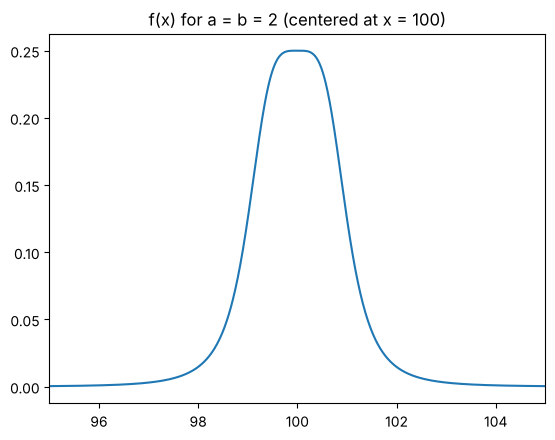

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.fft import fft, fftfreq, fftshift, ifftshift

SAMPLE_RATE = 100   # samples per unit of x
DURATION = 200      # length of the x interval
N = SAMPLE_RATE * DURATION
CENTER = DURATION / 2   # put the bump in the middle, as in the square-wave example

def generate_function(a, b, shift, sample_rate, duration):
    x = np.linspace(0, duration, sample_rate * duration, endpoint=False)
    y = 1.0 / (a**2 * (x - CENTER - shift)**4 + b**2)
    return x, y

x, y = generate_function(2, 2, 0, SAMPLE_RATE, DURATION)
plt.plot(x, y)
plt.xlim(CENTER - 5, CENTER + 5)
plt.title('f(x) for a = b = 2 (centered at x = %d)' % CENTER)
plt.show()

### The FFT

* `fft(y)` computes the transform; `fftfreq(N, 1 / SAMPLE_RATE)` gives the frequency of each output bin (exactly as in `scipy_fft.ipynb`).
* `fft` treats the **first sample** as the origin $x=0$. Our bump is centred in the middle of the array, so before the FFT we use **`ifftshift(y)`**, which rotates the array so the middle sample comes first. The bump is then centred at the origin, as in the formula $f(x)$.
* After the FFT, **`fftshift`** reorders the output from negative to positive frequency, so the plot is a single continuous curve (without it, `plt.plot` draws a line from the last positive frequency back to the most negative one).
* Dividing by `SAMPLE_RATE` (i.e. multiplying by the step $dx$) makes the values independent of how finely we sample, so $F(0)$ equals the area under $f$.

In [2]:
def compute_fft(y):
    yf = fftshift(fft(ifftshift(y))) / SAMPLE_RATE
    xf = fftshift(fftfreq(N, 1 / SAMPLE_RATE))
    return xf, yf

def plot_fft(ax, xf, yf, title):
    ax.plot(xf, yf.real, label='Real')
    ax.plot(xf, yf.imag, label='Imaginary')
    ax.plot(xf, np.abs(yf), 'k--', label='Absolute value')
    ax.set_title(title)
    ax.legend()
    ax.grid()

### Why `ifftshift` matters
Here is case 1 *without* `ifftshift`, i.e. the way the square-wave example did it. The absolute value is correct, but the real part flips sign from one frequency bin to the next (it is multiplied by $(-1)^m$), because the bump is not at the origin from the FFT's point of view (it sits at $x = 100$, which is a shift).

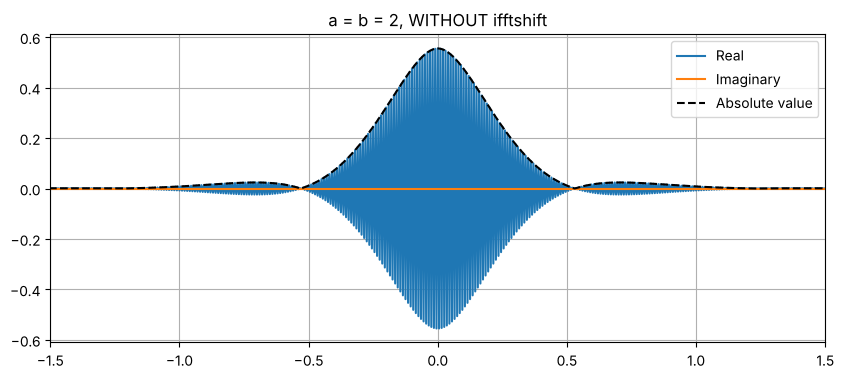

In [3]:
yf_raw = fftshift(fft(y)) / SAMPLE_RATE
xf = fftshift(fftfreq(N, 1 / SAMPLE_RATE))

fig, ax = plt.subplots(figsize=(10, 4))
plot_fft(ax, xf, yf_raw, 'a = b = 2, WITHOUT ifftshift')
ax.set_xlim(-1.5, 1.5)
plt.show()

### Case 1: $a = b = 2$

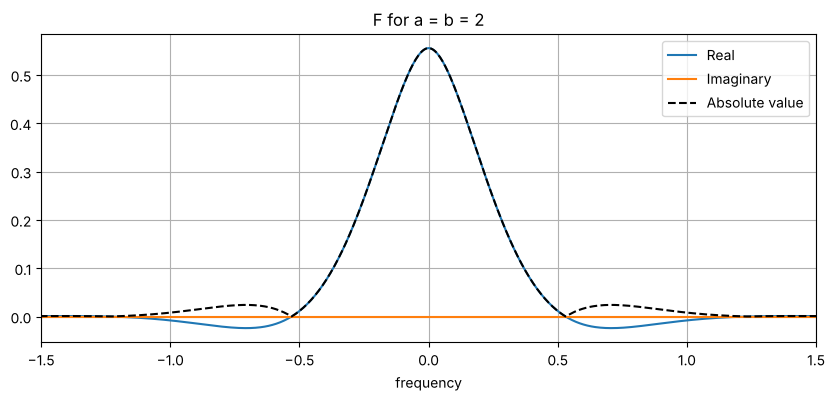

F(0) = 0.5553602006031282
largest |imaginary part| = 9.584000260076664e-16


In [4]:
x, y1 = generate_function(2, 2, 0, SAMPLE_RATE, DURATION)
xf, yf1 = compute_fft(y1)

fig, ax = plt.subplots(figsize=(10, 4))
plot_fft(ax, xf, yf1, 'F for a = b = 2')
ax.set_xlim(-1.5, 1.5)
ax.set_xlabel('frequency')
plt.show()

print('F(0) =', yf1[N//2].real)
print('largest |imaginary part| =', np.abs(yf1.imag).max())

$f$ is symmetric (even) around its centre, so its Fourier transform is **real**: the imaginary part is zero and the absolute value lies on the real part (it is its mirror image where the real part dips slightly below zero).

### Case 2: $a = 1$, $b = 2$

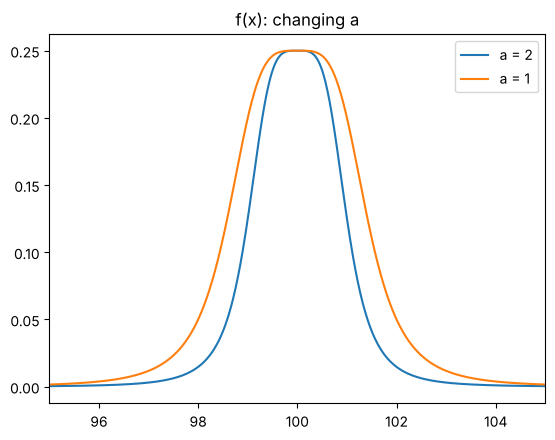

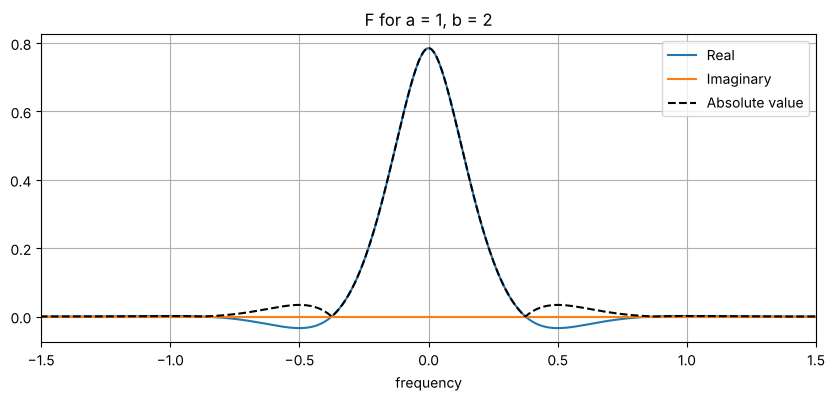

F(0) = 0.7853974967307863


In [5]:
x, y2 = generate_function(1, 2, 0, SAMPLE_RATE, DURATION)
xf, yf2 = compute_fft(y2)

plt.plot(x, y1, label='a = 2')
plt.plot(x, y2, label='a = 1')
plt.xlim(CENTER - 5, CENTER + 5)
plt.legend(); plt.title('f(x): changing a'); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
plot_fft(ax, xf, yf2, 'F for a = 1, b = 2')
ax.set_xlim(-1.5, 1.5)
ax.set_xlabel('frequency')
plt.show()

print('F(0) =', yf2[N//2].real)

With $a = 1$ the function is **wider** (it stays close to its peak $1/b^2$ for longer). Its transform becomes **narrower and taller**: this is the same theorem as in the square-wave example: stretching a function in $x$ compresses its transform in frequency. $F(0)$ is the area under $f$, which grew. $f$ is still symmetric, so $F$ is still real.

### Case 3: $a = 1$, $b = 2$, $x \to x - 2$

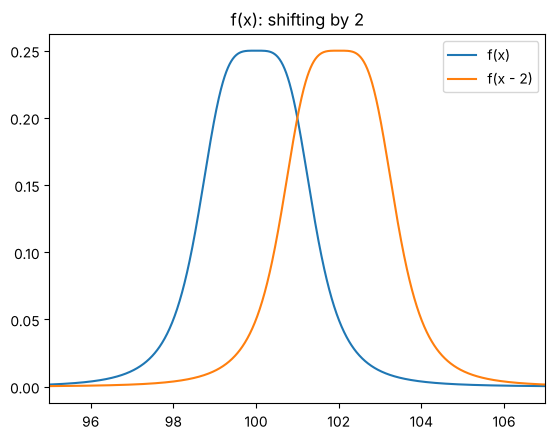

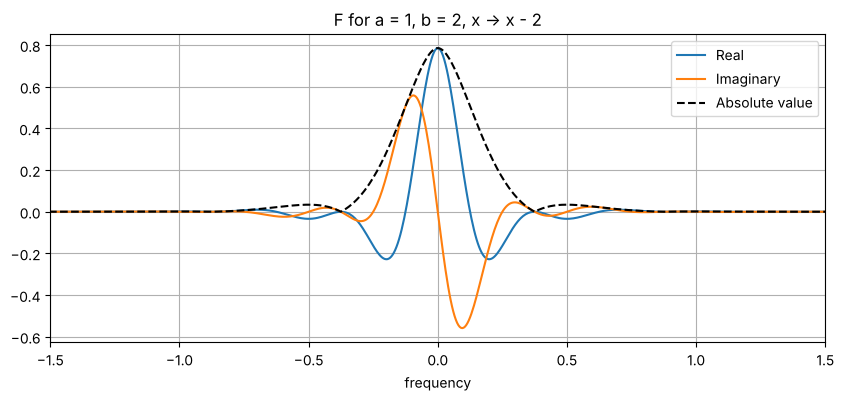

largest difference in absolute value vs case 2 = 1.6096169952461992e-09


In [6]:
x, y3 = generate_function(1, 2, 2, SAMPLE_RATE, DURATION)
xf, yf3 = compute_fft(y3)

plt.plot(x, y2, label='f(x)')
plt.plot(x, y3, label='f(x - 2)')
plt.xlim(CENTER - 5, CENTER + 7)
plt.legend(); plt.title('f(x): shifting by 2'); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
plot_fft(ax, xf, yf3, 'F for a = 1, b = 2, x -> x - 2')
ax.set_xlim(-1.5, 1.5)
ax.set_xlabel('frequency')
plt.show()

print('largest difference in absolute value vs case 2 =', np.abs(np.abs(yf3) - np.abs(yf2)).max())

Shifting the function **does not change the absolute value** (it is identical to case 2). It only changes the phase: the transform is multiplied by $e^{-i\,2\pi\,\nu\,\cdot 2}$, where $\nu$ is the frequency. So the real and imaginary parts now **oscillate** (period $1/2$ in frequency), inside the envelope given by the absolute value, and the imaginary part is no longer zero.

### The three versions, one below the other

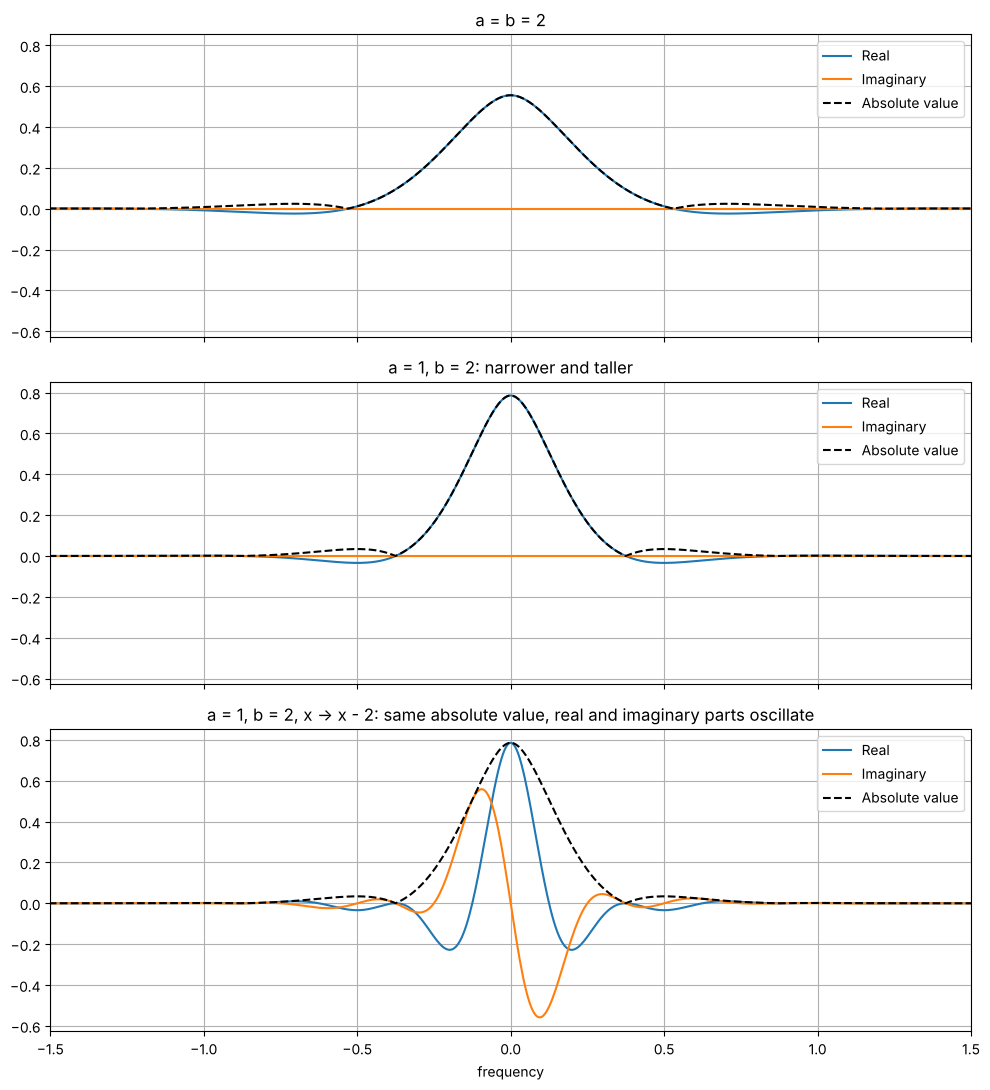

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(10, 11), sharex=True, sharey=True)
plot_fft(axes[0], xf, yf1, 'a = b = 2')
plot_fft(axes[1], xf, yf2, 'a = 1, b = 2: narrower and taller')
plot_fft(axes[2], xf, yf3, 'a = 1, b = 2, x -> x - 2: same absolute value, real and imaginary parts oscillate')
axes[2].set_xlim(-1.5, 1.5)
axes[2].set_xlabel('frequency')
plt.tight_layout()
plt.show()

### Summary
* **$a = b = 2$**: $F$ is real (the imaginary part is zero), a peak at frequency 0 that falls off and dips slightly below zero.
* **$a \to 1$**: $f$ is wider, so $F$ is narrower and taller; it is still real.
* **$x \to x-2$**: the absolute value of $F$ is unchanged; only the phase changes, so the real and imaginary parts oscillate.